Market Risk During Financial Stress

A Comparative Analysis of Volatility, Drawdowns, Recovery and Market Sensitivity

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

START_DATE = "2020-01-01"
END_DATE = "2021-12-31"

STRESS_START = "2020-02-20"
STRESS_END = "2020-03-23"

print("Market Risk During Financial Stress")
print("Analysis period:", START_DATE, "to", END_DATE)
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)


Market Risk During Financial Stress
Analysis period: 2020-01-01 to 2021-12-31
Pandas version: 2.2.3
NumPy version: 2.1.3


In [ ]:

from google.colab import files

uploaded = files.upload()

print("Number of files uploaded:", len(uploaded))
print("Uploaded filenames:")

for filename in uploaded.keys():
    print(filename)


Saving RELIANCE_Historical_01012020_to_31122021.xlsx to RELIANCE_Historical_01012020_to_31122021 (1).xlsx
Saving HDFCBANK_Historical_01012020_to_31122021.xlsx to HDFCBANK_Historical_01012020_to_31122021 (1).xlsx
Saving INFY_Historical_01012020_to_31122021.xlsx to INFY_Historical_01012020_to_31122021 (1).xlsx
Saving TMPV_Historical_01012020_to_31122021.xlsx to TMPV_Historical_01012020_to_31122021 (1).xlsx
Saving NIFTY_50_Historical_01012020_to_31122021.xlsx to NIFTY_50_Historical_01012020_to_31122021 (1).xlsx
Number of files uploaded: 5
Uploaded filenames:
RELIANCE_Historical_01012020_to_31122021 (1).xlsx
HDFCBANK_Historical_01012020_to_31122021 (1).xlsx
INFY_Historical_01012020_to_31122021 (1).xlsx
TMPV_Historical_01012020_to_31122021 (1).xlsx
NIFTY_50_Historical_01012020_to_31122021 (1).xlsx


In [ ]:


def find_file(prefix):
    matches = [
        name for name in uploaded.keys()
        if name.upper().startswith(prefix.upper())
        and name.lower().endswith((".xlsx", ".xls"))
    ]

    if not matches:
        raise FileNotFoundError(
            f"Could not find an uploaded file starting with {prefix}"
        )

    return matches[0]


reliance = pd.read_excel(find_file("RELIANCE_Historical"))
hdfc = pd.read_excel(find_file("HDFCBANK_Historical"))
infosys = pd.read_excel(find_file("INFY_Historical"))
tata = pd.read_excel(find_file("TMPV_Historical"))
nifty = pd.read_excel(find_file("NIFTY_50_Historical"))

print("All five Excel files loaded successfully!")
print("Reliance:", reliance.shape)
print("HDFC Bank:", hdfc.shape)
print("Infosys:", infosys.shape)
print("Tata Motors:", tata.shape)
print("NIFTY 50:", nifty.shape)


All five Excel files loaded successfully!
Reliance: (504, 14)
HDFC Bank: (503, 14)
Infosys: (501, 14)
Tata Motors: (502, 14)
NIFTY 50: (500, 7)


In [ ]:

print("RELIANCE COLUMNS")
print(reliance.columns.tolist())

print("\nHDFC BANK COLUMNS")
print(hdfc.columns.tolist())

print("\nINFOSYS COLUMNS")
print(infosys.columns.tolist())

print("\nTATA MOTORS COLUMNS")
print(tata.columns.tolist())

print("\nNIFTY 50 COLUMNS")
print(nifty.columns.tolist())


RELIANCE COLUMNS
['DATE', 'SERIES', 'OPEN', 'HIGH', 'LOW', 'PREV. CLOSE', 'LTP', 'CLOSE', 'VWAP', 'VOLUME', 'VALUE', 'NO OF TRADES', 'DELIVERY QTY', 'DELIVERY %']

HDFC BANK COLUMNS
['DATE', 'SERIES', 'OPEN', 'HIGH', 'LOW', 'PREV. CLOSE', 'LTP', 'CLOSE', 'VWAP', 'VOLUME', 'VALUE', 'NO OF TRADES', 'DELIVERY QTY', 'DELIVERY %']

INFOSYS COLUMNS
['DATE', 'SERIES', 'OPEN', 'HIGH', 'LOW', 'PREV. CLOSE', 'LTP', 'CLOSE', 'VWAP', 'VOLUME', 'VALUE', 'NO OF TRADES', 'DELIVERY QTY', 'DELIVERY %']

TATA MOTORS COLUMNS
['DATE', 'SERIES', 'OPEN', 'HIGH', 'LOW', 'PREV. CLOSE', 'LTP', 'CLOSE', 'VWAP', 'VOLUME', 'VALUE', 'NO OF TRADES', 'DELIVERY QTY', 'DELIVERY %']

NIFTY 50 COLUMNS
['DATE', 'OPEN', 'HIGH', 'LOW', 'CLOSE', 'SHARES TRADED', 'TURNOVER (INR CR)']


In [ ]:


stock_data = {
    "Reliance": reliance,
    "HDFC Bank": hdfc,
    "Infosys": infosys,
    "Tata Motors": tata
}

clean_stocks = {}

for name, df in stock_data.items():
    df = df.copy()
    df.columns = df.columns.str.strip().str.upper()

    df["DATE"] = pd.to_datetime(df["DATE"], errors="coerce")

    df = df[df["SERIES"].astype(str).str.strip() == "EQ"]

    df["CLOSE"] = pd.to_numeric(df["CLOSE"], errors="coerce")
    df["VOLUME"] = pd.to_numeric(df["VOLUME"], errors="coerce")

    df = df.dropna(subset=["DATE", "CLOSE"])
    df = df.drop_duplicates(subset=["DATE"], keep="last")
    df = df.sort_values("DATE")

    df = df[
        (df["DATE"] >= START_DATE) &
        (df["DATE"] <= END_DATE)
    ]

    clean_stocks[name] = df



nifty_clean = nifty.copy()
nifty_clean.columns = nifty_clean.columns.str.strip().str.upper()

nifty_clean["DATE"] = pd.to_datetime(
    nifty_clean["DATE"], errors="coerce"
)
nifty_clean["CLOSE"] = pd.to_numeric(
    nifty_clean["CLOSE"], errors="coerce"
)

nifty_clean = nifty_clean.dropna(subset=["DATE", "CLOSE"])
nifty_clean = nifty_clean.drop_duplicates(
    subset=["DATE"], keep="last"
)
nifty_clean = nifty_clean.sort_values("DATE")

nifty_clean = nifty_clean[
    (nifty_clean["DATE"] >= START_DATE) &
    (nifty_clean["DATE"] <= END_DATE)
]

print("Cleaning completed.")
print("\nRows after cleaning:")

for name, df in clean_stocks.items():
    print(name + ":", len(df))

print("NIFTY 50:", len(nifty_clean))


Cleaning completed.

Rows after cleaning:
Reliance: 500
HDFC Bank: 500
Infosys: 500
Tata Motors: 500
NIFTY 50: 500


In [ ]:


price_data = {}

for name, df in clean_stocks.items():
    price_data[name] = df.set_index("DATE")["CLOSE"]

price_data["NIFTY 50"] = nifty_clean.set_index("DATE")["CLOSE"]

prices = pd.DataFrame(price_data).sort_index()

print("Combined closing-price table")
print("Shape:", prices.shape)
print("\nFirst five rows:")
display(prices.head())

print("\nLast five rows:")
display(prices.tail())

print("\nMissing closing prices:")
display(prices.isna().sum())


Combined closing-price table
Shape: (500, 5)

First five rows:


,Reliance,HDFC Bank,Infosys,Tata Motors,NIFTY 50
DATE,,,,,
2020-01-01,1509.60,1278.60,736.85,184.45,12182.50
2020-01-02,1535.30,1286.75,734.70,193.75,12282.20
2020-01-03,1537.15,1268.40,746.00,191.10,12226.65
2020-01-06,1501.50,1240.95,738.85,185.65,11993.05
2020-01-07,1524.60,1260.60,727.90,184.70,12052.95



Last five rows:


,Reliance,HDFC Bank,Infosys,Tata Motors,NIFTY 50
DATE,,,,,
2021-12-27,2370.25,1450.80,1866.15,471.15,17086.25
2021-12-28,2398.40,1460.80,1888.00,480.20,17233.25
2021-12-29,2402.50,1453.85,1885.55,476.00,17213.60
2021-12-30,2359.10,1461.50,1892.85,470.40,17203.95
2021-12-31,2368.15,1479.40,1887.75,482.40,17354.05



Missing closing prices:


,0
Reliance,0
HDFC Bank,0
Infosys,0
Tata Motors,0
NIFTY 50,0


In [ ]:

# Calculate daily percentage returns

returns = prices.pct_change().dropna()

print("Daily returns calculated successfully.")
print("Shape:", returns.shape)

print("\nFirst five rows of daily returns:")
display((returns.head() * 100).round(3))

print("\nSummary statistics:")
display((returns * 100).describe().round(3))


Daily returns calculated successfully.
Shape: (499, 5)

First five rows of daily returns:


,Reliance,HDFC Bank,Infosys,Tata Motors,NIFTY 50
DATE,,,,,
2020-01-02,1.702,0.637,-0.292,5.042,0.818
2020-01-03,0.120,-1.426,1.538,-1.368,-0.452
2020-01-06,-2.319,-2.164,-0.958,-2.852,-1.911
2020-01-07,1.538,1.583,-1.482,-0.512,0.499
2020-01-08,-0.751,-0.262,-1.333,-1.164,-0.229



Summary statistics:


,Reliance,HDFC Bank,Infosys,Tata Motors,NIFTY 50
count,499.000,499.000,499.000,499.000,499.000
mean,0.119,0.052,0.209,0.254,0.083
std,2.384,2.120,2.011,3.534,1.560
min,-13.154,-12.607,-10.039,-14.360,-12.980
25%,-0.979,-0.997,-0.792,-1.406,-0.462
50%,0.161,0.013,0.154,0.243,0.170
75%,1.196,1.088,1.041,1.707,0.804
max,14.718,11.600,12.033,20.447,8.763


In [ ]:

# Defining the three study periods

pre_stress = returns.loc["2020-01-01":"2020-02-19"]
stress = returns.loc["2020-02-20":"2020-03-23"]
recovery = returns.loc["2020-03-24":"2021-12-31"]

# Calculate annualized volatility

volatility = pd.DataFrame({
    "Pre-stress (%)": pre_stress.std() * np.sqrt(252) * 100,
    "Stress (%)": stress.std() * np.sqrt(252) * 100,
    "Recovery (%)": recovery.std() * np.sqrt(252) * 100
})

print("Annualized volatility by period:")
display(volatility.round(2))


Annualized volatility by period:


,Pre-stress (%),Stress (%),Recovery (%)
Reliance,24.41,85.45,34.08
HDFC Bank,18.44,65.06,31.62
Infosys,20.97,66.40,29.34
Tata Motors,52.82,82.25,52.85
NIFTY 50,14.49,66.04,20.41


In [ ]:

# Calculate maximum drawdown for each asset

drawdown_results = {}

for asset in prices.columns:
    asset_prices = prices[asset]

    running_peak = asset_prices.cummax()
    drawdown = (asset_prices / running_peak) - 1

    drawdown_results[asset] = drawdown.min() * 100

max_drawdown = pd.DataFrame.from_dict(
    drawdown_results,
    orient="index",
    columns=["Maximum Drawdown (%)"]
)

max_drawdown.index.name = "Asset"

print("Maximum drawdown during 2020–2021:")
display(max_drawdown.round(2))


Maximum drawdown during 2020–2021:


,Maximum Drawdown (%)
Asset,
Reliance,-44.08
HDFC Bank,-40.47
Infosys,-34.23
Tata Motors,-67.41
NIFTY 50,-38.44


In [ ]:

# Calculate recovery time after the maximum drawdown

recovery_results = {}

for asset in prices.columns:
    asset_prices = prices[asset].dropna()

    running_peak = asset_prices.cummax()
    drawdown = asset_prices / running_peak - 1

    trough_date = drawdown.idxmin()
    previous_peak = running_peak.loc[trough_date]

    later_prices = asset_prices.loc[trough_date:]
    recovered = later_prices[later_prices >= previous_peak]

    if len(recovered) > 0:
        recovery_date = recovered.index[0]
        recovery_days = (recovery_date - trough_date).days
    else:
        recovery_date = None
        recovery_days = None

    recovery_results[asset] = {
        "Trough date": trough_date.date(),
        "Recovery date": (
            recovery_date.date() if recovery_date is not None else "Not recovered"
        ),
        "Recovery days": recovery_days
    }

recovery_table = pd.DataFrame(recovery_results).T
recovery_table.index.name = "Asset"

print("Recovery time after maximum drawdown:")
display(recovery_table)


Recovery time after maximum drawdown:


,Trough date,Recovery date,Recovery days
Asset,,,
Reliance,2020-03-23,2020-06-05,74
HDFC Bank,2020-03-24,2020-11-06,227
Infosys,2020-03-23,2020-07-15,114
Tata Motors,2020-04-03,2021-01-11,283
NIFTY 50,2020-03-23,2020-11-09,231


In [ ]:

# Calculate correlation matrix using daily returns

stock_returns = returns[
    ["Reliance", "HDFC Bank", "Infosys", "Tata Motors"]
]

correlation_matrix = stock_returns.corr()

print("Correlation matrix for the four stocks:")
display(correlation_matrix.round(3))


Correlation matrix for the four stocks:


,Reliance,HDFC Bank,Infosys,Tata Motors
Reliance,1.000,0.496,0.415,0.394
HDFC Bank,0.496,1.000,0.411,0.432
Infosys,0.415,0.411,1.000,0.352
Tata Motors,0.394,0.432,0.352,1.000


In [ ]:

# Calculate full-period beta and market correlation

market_returns = returns["NIFTY 50"]

market_results = {}

for stock in ["Reliance", "HDFC Bank", "Infosys", "Tata Motors"]:
    stock_returns = returns[stock]

    beta_value = (
        stock_returns.cov(market_returns)
        / market_returns.var()
    )

    correlation_value = stock_returns.corr(market_returns)

    market_results[stock] = {
        "Beta": beta_value,
        "Correlation with NIFTY 50": correlation_value
    }

market_table = pd.DataFrame(market_results).T
market_table.index.name = "Stock"

print("Full-period beta and market correlation:")
display(market_table.round(3))


Full-period beta and market correlation:


,Beta,Correlation with NIFTY 50
Stock,,
Reliance,1.096,0.717
HDFC Bank,1.094,0.805
Infosys,0.835,0.648
Tata Motors,1.386,0.612


In [ ]:

# Calculate beta and correlation during the stress period

stress_returns = returns.loc["2020-02-20":"2020-03-23"]

stress_market_returns = stress_returns["NIFTY 50"]

stress_results = {}

for stock in ["Reliance", "HDFC Bank", "Infosys", "Tata Motors"]:
    stock_stress_returns = stress_returns[stock]

    stress_beta = (
        stock_stress_returns.cov(stress_market_returns)
        / stress_market_returns.var()
    )

    stress_correlation = (
        stock_stress_returns.corr(stress_market_returns)
    )

    stress_results[stock] = {
        "Stress beta": stress_beta,
        "Stress correlation": stress_correlation
    }

stress_market_table = pd.DataFrame(stress_results).T
stress_market_table.index.name = "Stock"

print("Beta and correlation during COVID-19 stress:")
display(stress_market_table.round(3))


Beta and correlation during COVID-19 stress:


,Stress beta,Stress correlation
Stock,,
Reliance,1.168,0.903
HDFC Bank,0.814,0.827
Infosys,0.901,0.896
Tata Motors,1.064,0.854


In [ ]:

# Compare average trading volume before and during the stress period

volume_results = {}

for name, df in clean_stocks.items():
    pre_volume = df.loc[
        df["DATE"] < STRESS_START, "VOLUME"
    ].mean()

    stress_volume = df.loc[
        (df["DATE"] >= STRESS_START) &
        (df["DATE"] <= STRESS_END), "VOLUME"
    ].mean()

    if pd.notna(pre_volume) and pre_volume != 0:
        change_percent = (
            (stress_volume - pre_volume) / pre_volume
        ) * 100
    else:
        change_percent = np.nan

    volume_results[name] = {
        "Pre-stress average volume": pre_volume,
        "Stress average volume": stress_volume,
        "Change (%)": change_percent
    }

volume_table = pd.DataFrame(volume_results).T
volume_table.index.name = "Stock"

print("Trading volume comparison:")
display(volume_table.round(2))


Trading volume comparison:


,Pre-stress average volume,Stress average volume,Change (%)
Stock,,,
Reliance,8394366.78,19029818.33,126.70
HDFC Bank,5917732.54,17894881.43,202.39
Infosys,6915444.76,12140538.14,75.56
Tata Motors,43295261.46,78774800.14,81.95


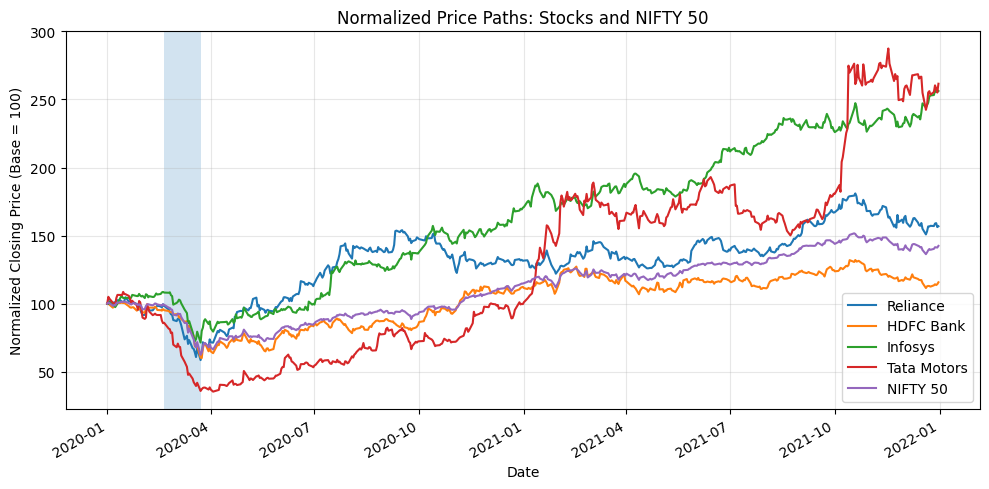

In [ ]:

#normalized closing prices

normalized_prices = prices / prices.iloc[0] * 100

normalized_prices.plot(figsize=(10, 5))

plt.axvspan(
    pd.Timestamp("2020-02-20"),
    pd.Timestamp("2020-03-23"),
    alpha=0.2
)

plt.title("Normalized Price Paths: Stocks and NIFTY 50")
plt.xlabel("Date")
plt.ylabel("Normalized Closing Price (Base = 100)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## Key Findings

- Annualized volatility increased sharply for the NIFTY 50 and all four stocks during the COVID-19 stress period.
- Maximum drawdowns ranged from 34.2% for Infosys to 67.4% for Tata Motors, compared with 38.4% for the NIFTY 50.
- Recovery times varied substantially, from 74 calendar days for Reliance to 283 days for Tata Motors.
- Reliance, HDFC Bank and Tata Motors had full-period betas above 1, while Infosys had a beta below 1.
- Correlations among the four companies were positive but moderate, suggesting that their returns did not move identically.

## Risk Management Interpretation

- **Volatility:** Increased sharply during the COVID-19 market crash.
- **Drawdown and recovery:** Tata Motors experienced the largest drawdown (67.4%) and longest recovery (283 days).
- **Market sensitivity:** Tata Motors had the highest full-period beta (1.386), while Infosys had the lowest (0.835).
- **Diversification:** The four stocks had positive but moderate correlations (0.352–0.496), indicating that their returns did not move identically.

**Key takeaway:** Market risk should be assessed using multiple measures rather than volatility alone.

## Data Sources

- **Company data:** NSE historical daily equity data for Reliance Industries, HDFC Bank, Infosys and Tata Motors (2020–2021).
- **Market benchmark:** NIFTY 50 historical daily data (2020–2021).

